In [1]:
import torch

In [2]:
torch.__version__

'2.10.0+cu128'

### Libraries

In [4]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF
import random
from torch.utils.data import random_split

In [5]:
torch.manual_seed(42)
np.random.seed(42)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else "cpu")
print(device)

cuda


### Learning Curve Plot

In [6]:
def learning_curve_plot(title, train_losses, test_losses, train_accuracy, test_accuracy, batch_size, learning_rate, training_time_seconds):
  fsizes = [13, 10, 8]
  fig, axs = plt.subplots(1, 2, figsize=(12, 4))
  fig.suptitle(title, y=1.1, fontsize=fsizes[0])
  formatted_time = f"{training_time_seconds // 3600}h {(training_time_seconds % 3600) // 60}min"
  sub = f'| Batch size:{batch_size} | Learning rate:{learning_rate} | '
  sub += f'Number of Epochs:{len(train_losses)} | Training time:{formatted_time} |'
  fig.text(0.5, 0.99, sub, ha='center', fontsize=fsizes[1])
  x = range(1, len(train_losses)+1)
  axs[0].plot(x, train_losses, label=f'Final train loss: {train_losses[-1]:.4f}')
  axs[0].plot(x, test_losses, label=f'Final test loss: {test_losses[-1]:.4f}')
  axs[0].set_title('Losses', fontsize=fsizes[1])
  axs[0].set_xlabel('Epoch', fontsize=fsizes[1])
  axs[0].set_ylabel('Loss', fontsize=fsizes[1])
  axs[0].legend(fontsize=fsizes[2])
  axs[0].tick_params(axis='both', labelsize=fsizes[2])
  axs[0].grid()
  axs[1].plot(x, train_accuracy, label=f'Final train dice: {train_accuracy[-1]:.4f}%')
  axs[1].plot(x, test_accuracy, label=f'Final test dice: {test_accuracy[-1]:.4f}%')
  axs[1].set_title('Dice Score', fontsize=fsizes[1])
  axs[1].set_xlabel('Epoch', fontsize=fsizes[1])
  axs[1].set_ylabel('Dice Score (%)', fontsize=fsizes[2])
  axs[1].legend(fontsize=fsizes[2])
  axs[1].tick_params(axis='both', labelsize=fsizes[2])
  axs[1].grid()

In [7]:
BATCH_SIZE = 8
LR = 1e-3
EPOCHS = 100

### Data Loader (Old - Without Augmentation)

In [8]:
class WarwickData(Dataset):
    def __init__(self, root, split="Train", augment=False):
        self.split = split
        self.augment = augment
        self.split_path = os.path.join(root, split)
        # Use sorted to ensure consistent indexing across runs
        self.image_files = sorted([f for f in os.listdir(self.split_path) if f.startswith("image") and f.endswith(".png")])
        
        self.normalize = transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        label_name = img_name.replace("image", "label")
        
        img_path = os.path.join(self.split_path, img_name)
        label_path = os.path.join(self.split_path, label_name)

        image = Image.open(img_path).convert("RGB")
        label = Image.open(label_path).convert("L")

        if self.augment:
            if random.random() > 0.5: image = TF.hflip(image); label = TF.hflip(label)
            if random.random() > 0.5: image = TF.vflip(image); label = TF.vflip(label)
            if random.random() > 0.5:
                angle = random.uniform(-15, 15)
                image = TF.rotate(image, angle)
                label = TF.rotate(label, angle)
            image = transforms.ColorJitter(brightness=0.2, contrast=0.2)(image)

        image = TF.to_tensor(image)
        label = TF.to_tensor(label)
        image = self.normalize(image)
        mask = (label > 0.5).float()
        return image, mask

# Consistent Data Loading Setup
data_root = "/kaggle/input/datasets/fahimrayhan/warwick-qu-dataset/WARWICK"
# Data Augmentations False
full_train_ds = WarwickData(data_root, split="Train", augment=False)
test_ds = WarwickData(data_root, split="Test", augment=False)

# Proper validation split to avoid data leakage/augmentation in val
train_idx, val_idx = random_split(range(len(full_train_ds)), [0.8, 0.2], generator=torch.Generator().manual_seed(42))

# Create Subsets
from torch.utils.data import Subset
train_subset = Subset(full_train_ds, train_idx)
val_subset = Subset(WarwickData(data_root, split="Train", augment=False), val_idx)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoaders ready: {len(train_subset)} train, {len(val_subset)} val, {len(test_ds)} test samples.")

DataLoaders ready: 68 train, 17 val, 60 test samples.


In [9]:
# Print shape of a single image
images, masks = next(iter(train_loader))

images[0].shape

torch.Size([3, 128, 128])

### Data Loader New (With Augmentation)

In [10]:
# class AugmentedWarWickDataset(Dataset):
#   def __init__(self, root, split="Train", augment=False):
#     self.split = split
#     self.augment = augment
#     self.split_path = os.path.join(root, split)
#     self.image_files = sorted([
#         f for f in os.listdir(self.split_path)
#         if f.startswith("image") and f.endswith(".png")
#     ])

#   def __len__(self):
#     return len(self.image_files)

#   def __getitem__(self, idx):
#     img_name = self.image_files[idx]
#     label_name = img_name.replace("image", "label")
#     img_path = os.path.join(self.split_path, img_name)
#     label_path = os.path.join(self.split_path, label_name)

#     image = Image.open(img_path).convert("RGB")
#     label = Image.open(label_path).convert("L")

#     if self.split == "Train" and self.augment:
#         if random.random() > 0.5:
#             image = TF.hflip(image)
#             label = TF.hflip(label)
#         if random.random() > 0.5:
#             image = TF.vflip(image)
#             label = TF.vflip(label)
#         if random.random() > 0.5:
#             angle = random.uniform(-15, 15)
#             image = TF.rotate(image, angle)
#             label = TF.rotate(label, angle)
#         color_jitter = transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1)
#         image = color_jitter(image)

#     image = TF.to_tensor(image)
#     label = TF.to_tensor(label)
#     image = TF.normalize(image, mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
#     mask = (label > 0.5).float()
#     return image, mask

# # Initialize loaders with the new augmented class
# train_ds = AugmentedWarWickDataset("./WARWICK", split="Train", augment=True)
# test_ds = AugmentedWarWickDataset("./WARWICK", split="Test", augment=False)

# train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
# test_loader = DataLoader(test_ds, batch_size=8, shuffle=False)

# print(f"New DataLoaders initialized. Augmentation: {'ENABLED' if train_ds.augment else 'DISABLED'}")

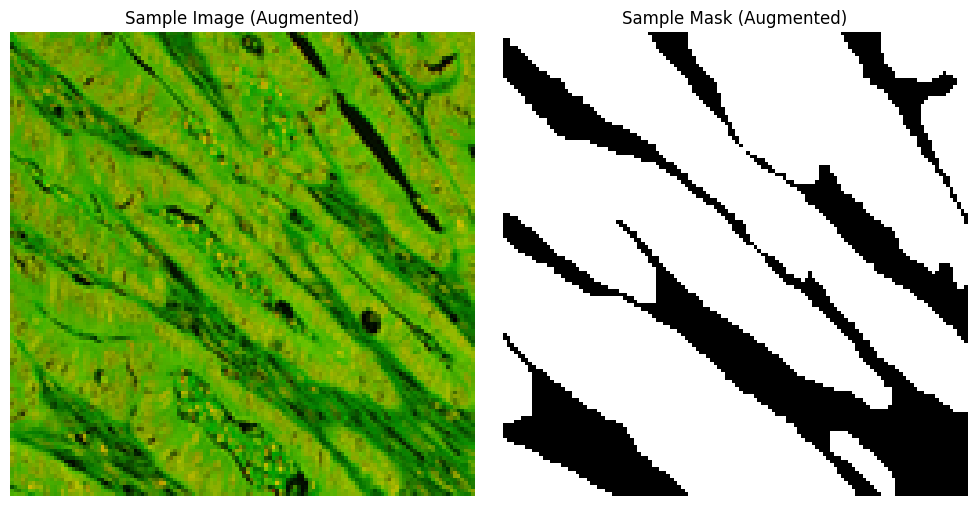

In [11]:
# Fetch a single batch to verify augmentation
images, masks = next(iter(train_loader))

# Select the first sample in the batch
# Denormalize image for visualization (mean=0.5, std=0.5 -> original = img * 0.5 + 0.5)
sample_img = images[0].permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5
sample_mask = masks[0].squeeze().cpu().numpy()

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(sample_img)
ax[0].set_title("Sample Image (Augmented)")
ax[0].axis("off")

ax[1].imshow(sample_mask, cmap="gray")
ax[1].set_title("Sample Mask (Augmented)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

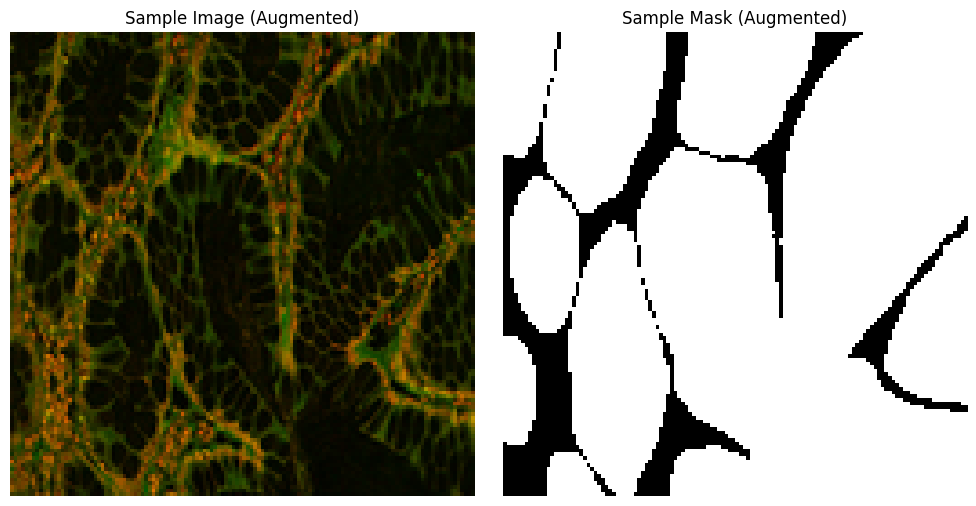

In [12]:
# Fetch a single batch
images, masks = next(iter(test_loader))

# Select the first sample in the batch
# Denormalize image for visualization (mean=0.5, std=0.5 -> original = img * 0.5 + 0.5)
sample_img = images[0].permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5
sample_mask = masks[0].squeeze().cpu().numpy()

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(sample_img)
ax[0].set_title("Sample Image (Augmented)")
ax[0].axis("off")

ax[1].imshow(sample_mask, cmap="gray")
ax[1].set_title("Sample Mask (Augmented)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [13]:
print(f"Number of training samples: {len(train_loader)}")
print(f"Number of validation samples: {len(val_loader)}")
print(f"Number of testing samples: {len(test_ds)}")

Number of training samples: 9
Number of validation samples: 3
Number of testing samples: 60


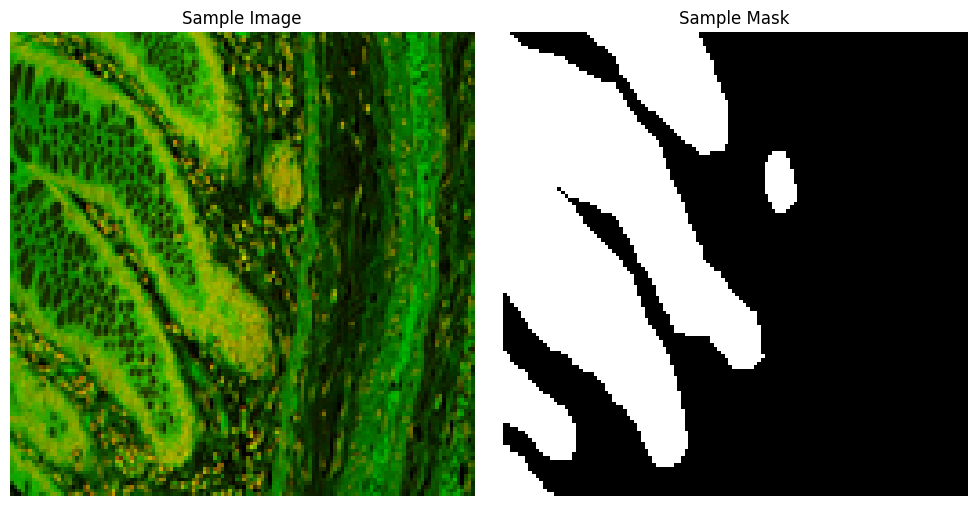

In [14]:
# Fetch a single batch
images, masks = next(iter(val_loader))

# Select the first sample in the batch
# Denormalize image for visualization (mean=0.5, std=0.5 -> original = img * 0.5 + 0.5)
sample_img = images[0].permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5
sample_mask = masks[0].squeeze().cpu().numpy()

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(sample_img)
ax[0].set_title("Sample Image")
ax[0].axis("off")

ax[1].imshow(sample_mask, cmap="gray")
ax[1].set_title("Sample Mask")
ax[1].axis("off")

plt.tight_layout()
plt.show()

### Dice Score Function
The Sørensen–Dice coefficient is used to evaluate the overlap between the predicted segmentation and the ground truth.

In [15]:
def dice_score(logits, targets, threshold=0.5, smooth=1e-6):
    # 1. Apply sigmoid to convert raw model output (logits) to probabilities [0, 1]
    probs = torch.sigmoid(logits)
    
    # 2. Apply threshold to get binary mask
    preds = (probs > threshold).float()
    targets = (targets > 0.5).float()

    # Flatten tensors
    preds = preds.view(-1)
    targets = targets.view(-1)

    intersection = (preds * targets).sum()
    dice = (2. * intersection + smooth) / (preds.sum() + targets.sum() + smooth)
    
    return dice.item()

### Defining the models

#### Semantic Segmentation

In [16]:
class SimpleSegNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 1, 1),
            # nn.Sigmoid()
        )
    def forward(self, x):
      return self.dec(self.enc(x))

#### Skip Connection

In [17]:
class UNetSkip(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU()
          )
        self.pool = nn.MaxPool2d(2)
        self.e2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU()
          )

        self.up1 = nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1)
        self.d1 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU()
          ) # 64 because of concatenation
        self.out = nn.Sequential(
            nn.Conv2d(32, 1, 1),
            # nn.Sigmoid()
          )

    def forward(self, x):
        e1_feat = self.e1(x)
        e2_feat = self.e2(self.pool(e1_feat))

        d1_feat = self.up1(e2_feat)
        # Requirement: Skip connection by concatenation
        d1_feat = torch.cat([d1_feat, e1_feat], dim=1)
        return self.out(self.d1(d1_feat))

#### Residual Connection

In [18]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super(ResBlock, self).__init__()

        self.shortcut = nn.Sequential()
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=1, bias=False),
                nn.BatchNorm2d(out_ch)
            )

        self.conv_path = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch)
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        # Residual Connection: Addition of input (shortcut) and output of conv layers
        residual = self.shortcut(x)
        out = self.conv_path(x)
        out += residual
        return self.relu(out)

In [19]:
class ResidualUNet(nn.Module):
    def __init__(self):
        super(ResidualUNet, self).__init__()

        # Encoder
        self.enc1 = ResBlock(3, 32)
        self.pool1 = nn.MaxPool2d(2) # 128 -> 64

        self.enc2 = ResBlock(32, 64)
        self.pool2 = nn.MaxPool2d(2) # 64 -> 32

        # self.bottleneck = ResBlock(64, 128)

        self.bottleneck = nn.Sequential(
            ResBlock(64, 128),
            nn.Dropout2d(p=0.1)
        )

        # Decoder (Using kernel 4, stride 2 as suggested)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1)
        self.dec2 = ResBlock(128, 64) # 64 (up) + 64 (skip)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1)
        self.dec1 = ResBlock(64, 32) # 32 (up) + 32 (skip)

        self.final_conv = nn.Conv2d(32, 1, kernel_size=1)
        # self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # Encoder path
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))

        # Bottleneck
        b = self.bottleneck(self.pool2(e2))

        # Decoder path with Skip Connections
        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1) # Concatenation from Ex 1.2
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1) # Concatenation from Ex 1.2
        d1 = self.dec1(d1)

        return self.final_conv(d1)

In [20]:
def visualize_results(model, dataset, num_samples=2):
    model.eval()
    scored_results = []
    with torch.no_grad():
        for i in range(len(dataset)):
            img, gt = dataset[i]
            pred = model(img.unsqueeze(0).to(device)).cpu()
            score = dice_score(pred, gt.unsqueeze(0))
            scored_results.append((score, img, gt, pred))

    scored_results.sort(key=lambda x: x[0])
    # Show 2 Best and 2 Worst
    to_show = scored_results[:2] + scored_results[-2:]



### Train Function

In [21]:
import time
from tqdm import tqdm
torch.manual_seed(42)

def train_and_evaluate(model, train_loader, val_loader, criterion, optimizer, epochs, scheduler=None):
    train_losses, val_losses = [], []
    train_dice_list, val_dice_list = [], []

    start_time = time.time()

    for epoch in range(epochs):
        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        running_dice = 0.0

        for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]"):
            images, masks = images.to(device), masks.to(device)

            optimizer.zero_grad()
            outputs = model(images) # Model outputs raw logits
            
            # BCEWithLogitsLoss is used here for stability
            loss = criterion(outputs, masks)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            # Ensure your dice_score function now applies sigmoid internally!
            running_dice += dice_score(outputs, masks)

        # Calculate average epoch training metrics
        train_losses.append(running_loss / len(train_loader))
        train_dice_list.append((running_dice / len(train_loader)) * 100)

        # --- Validation Phase (Instructor feedback: Use Val, not Test) ---
        model.eval()
        running_val_loss = 0.0
        running_val_dice = 0.0

        with torch.inference_mode():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                outputs = model(images)

                loss = criterion(outputs, masks)
                running_val_loss += loss.item()
                running_val_dice += dice_score(outputs, masks)

        # Calculate average epoch validation metrics
        val_losses.append(running_val_loss / len(val_loader))
        val_dice_list.append((running_val_dice / len(val_loader)) * 100)

        # --- Learning Rate Scheduler Step (Critical for Ex 1.4) ---
        if scheduler is not None:
            # We step based on validation Dice score
            scheduler.step(val_dice_list[-1])

        print(f"Epoch {epoch+1}: Train Loss: {train_losses[-1]:.4f} | Val Dice: {val_dice_list[-1]:.2f}%")

    total_time = time.time() - start_time
    return train_losses, val_losses, train_dice_list, val_dice_list, total_time

### Comparison Plotting

In [22]:
def show_results_summary(model, test_loader):
    model.eval()
    all_results = []

    with torch.no_grad():
        # Iterate through the loader (handles batches automatically)
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            
            # 1. Get raw output (logits)
            logits = model(images)
            
            # 2. Convert to probabilities for visualization
            probs = torch.sigmoid(logits)
            
            # 3. Calculate scores for the whole batch
            # Move to CPU for list storage
            images = images.cpu()
            masks = masks.cpu()
            probs = probs.cpu()
            logits = logits.cpu()

            # Process each image in the batch individually
            for j in range(images.size(0)):
                # We pass the individual logit and mask to dice_score
                score = dice_score(logits[j:j+1], masks[j:j+1])
                all_results.append((score, images[j], masks[j], probs[j]))

    # Sort all images by Dice Score
    all_results.sort(key=lambda x: x[0])

    # Select 2 Worst and 2 Best
    to_visualize = [all_results[0], all_results[1], all_results[-2], all_results[-1]]
    titles = ["Worst Case 1", "Worst Case 2", "Best Case 1", "Best Case 2"]

    for i, (score, img, mask, pred) in enumerate(to_visualize):
        # Pass to your updated plot_case function
        plot_case((i, score, pred.squeeze(), img, mask), titles[i])

In [23]:
def plot_case(case, title):
    idx, score, pred, img, gt = case
    # Denormalize image
    img_np = img.permute(1, 2, 0).numpy() * 0.5 + 0.5
    gt_np = gt.squeeze().numpy()
    pred_np = (pred > 0.5).float().numpy()

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{title} (Dice Score: {score:.4f})", fontsize=16)

    ax[0].imshow(img_np)
    ax[0].set_title("Input Image")
    ax[0].axis("off")

    ax[1].imshow(gt_np, cmap="gray")
    ax[1].set_title("Ground Truth")
    ax[1].axis("off")

    ax[2].imshow(pred_np, cmap="gray")
    ax[2].set_title("Network Output")
    ax[2].axis("off")
    plt.show()

Epoch 1/100 [Train]: 100%|██████████| 9/9 [00:02<00:00,  4.24it/s]


Epoch 1: Train Loss: 0.6927 | Val Dice: 62.02%


Epoch 2/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 30.88it/s]


Epoch 2: Train Loss: 0.6885 | Val Dice: 58.52%


Epoch 3/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 30.84it/s]


Epoch 3: Train Loss: 0.6706 | Val Dice: 58.27%


... (190 outputs left out)

Epoch 99/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 31.55it/s]


Epoch 99: Train Loss: 0.4044 | Val Dice: 76.47%


Epoch 100/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 30.40it/s]


Epoch 100: Train Loss: 0.4222 | Val Dice: 83.27%


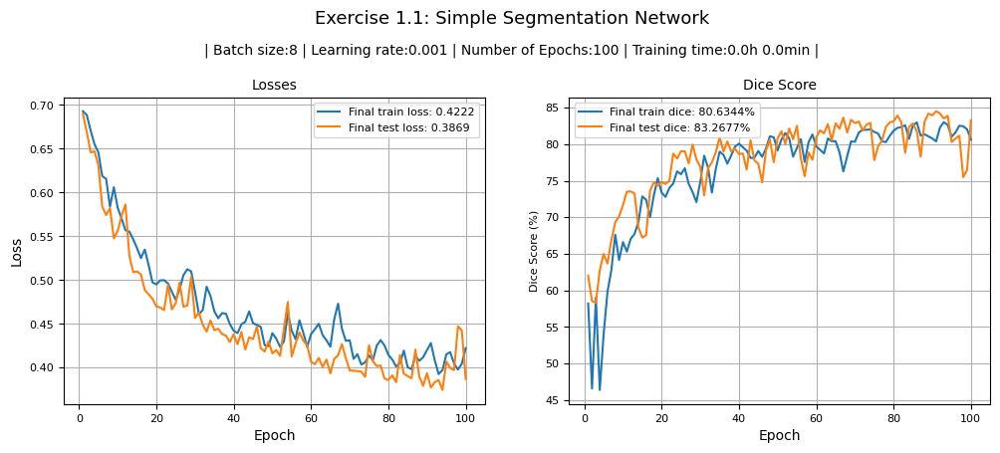

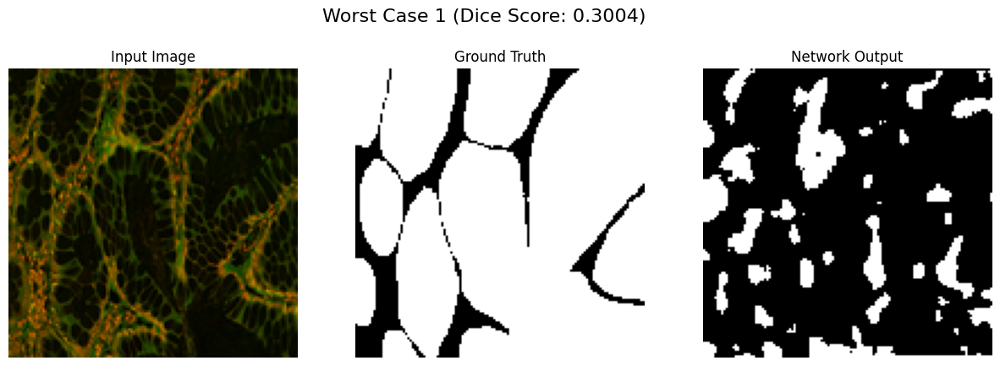

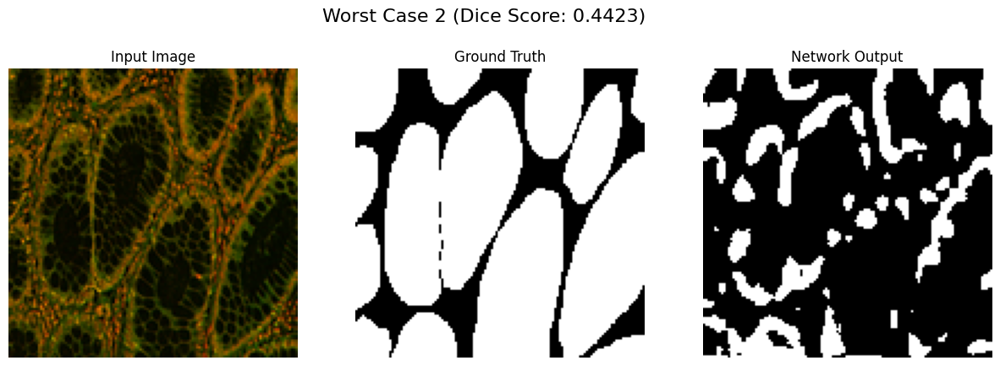

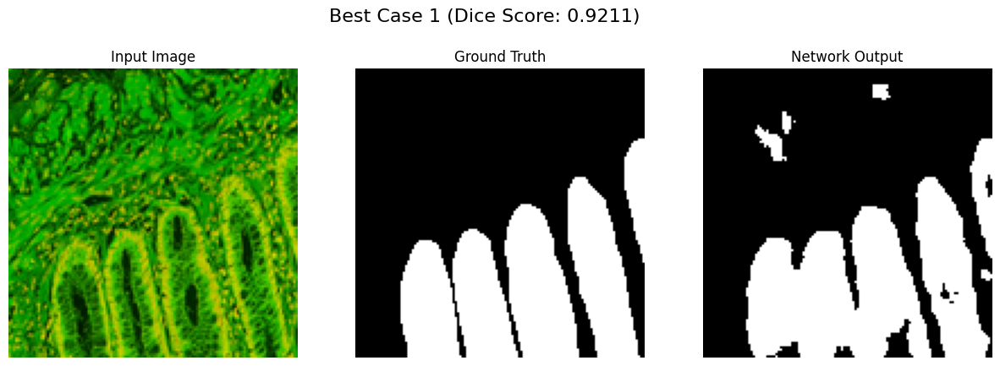

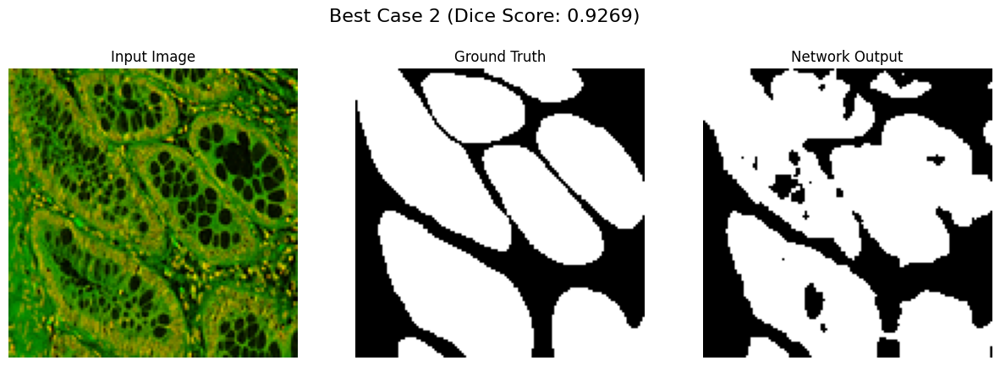

In [24]:
torch.manual_seed(42)
np.random.seed(42)

# 2. RE-INITIALIZE THE MODEL WITHOUT SIGMOID
model1 = SimpleSegNet().to(device) 

# 3. USE STABLE LOSS (Instructor requirement)
# This replaces nn.BCELoss()
criterion = nn.BCEWithLogitsLoss() 

optimizer = torch.optim.Adam(model1.parameters(), lr=LR)

# 4. RUN TRAINING WITH VALIDATION LOADER (Requirement 1.4 feedback)
# Note: We pass 'val_loader' instead of 'test_loader' to tune the model.
t_loss, v_loss, t_dice, v_dice, duration = train_and_evaluate(
    model1, train_loader, val_loader, criterion, optimizer, EPOCHS
)

# 5. PLOT LEARNING CURVES (Requirement: Replace 'Accuracy' with 'Dice')
learning_curve_plot(
    "Exercise 1.1: Simple Segmentation Network", 
    t_loss, v_loss, t_dice, v_dice, 
    BATCH_SIZE, LR, duration
)

# 6. QUALITATIVE INSPECTION (Requirement 1.1c)
# This will show the 2 best and 2 worst cases from the test set.
show_results_summary(model1, test_loader)

Epoch 1/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 22.45it/s]


Epoch 1: Train Loss: 0.6879 | Val Dice: 58.29%


Epoch 2/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 26.20it/s]


Epoch 2: Train Loss: 0.6629 | Val Dice: 59.02%


Epoch 3/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 26.08it/s]


Epoch 3: Train Loss: 0.6424 | Val Dice: 61.04%


... (190 outputs left out)

Epoch 99/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 29.39it/s]


Epoch 99: Train Loss: 0.3871 | Val Dice: 84.23%


Epoch 100/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 28.51it/s]


Epoch 100: Train Loss: 0.3848 | Val Dice: 84.19%


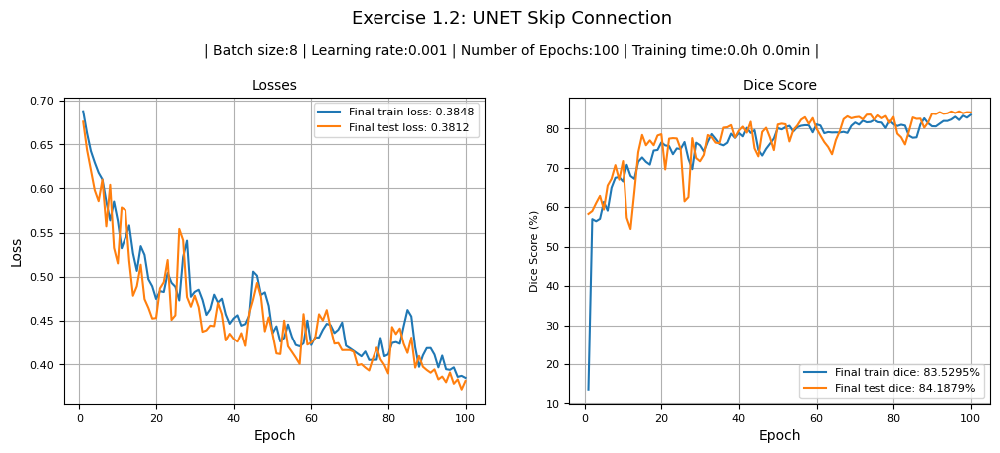

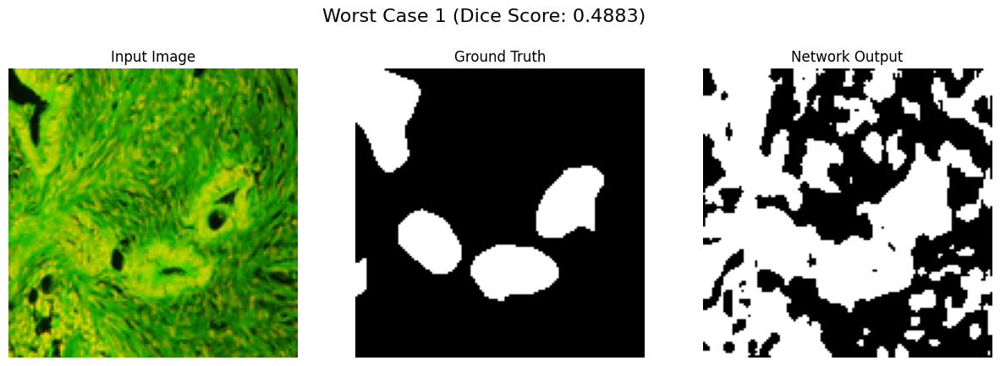

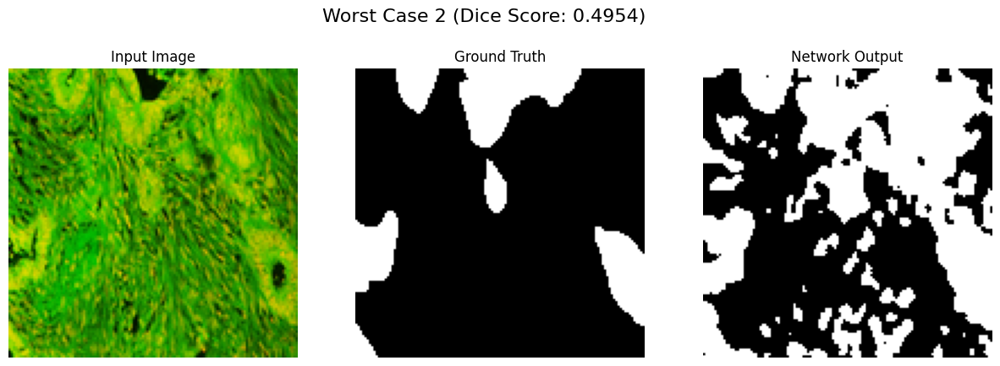

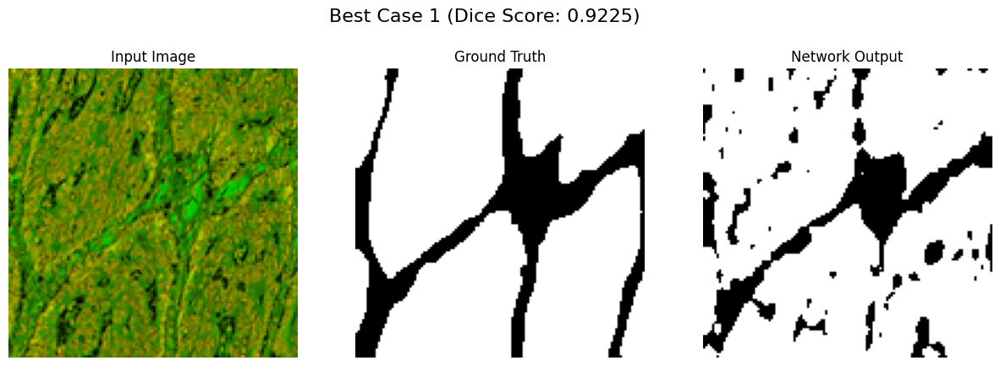

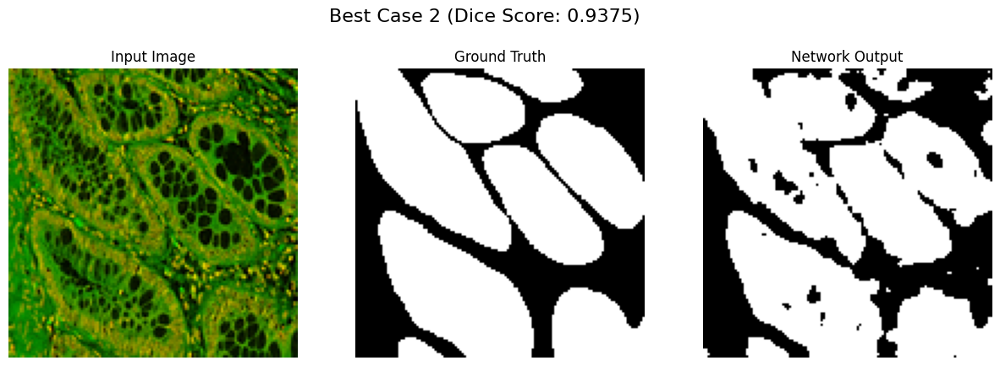

In [25]:
torch.manual_seed(42)
np.random.seed(42)

model2 = UNetSkip().to(device)
criterion = nn.BCEWithLogitsLoss() 

optimizer = torch.optim.Adam(model2.parameters(), lr=LR)

# 4. RUN TRAINING WITH VALIDATION LOADER (Requirement 1.4 feedback)
# Note: We pass 'val_loader' instead of 'test_loader' to tune the model.
t_loss, v_loss, t_dice, v_dice, duration = train_and_evaluate(
    model2, train_loader, val_loader, criterion, optimizer, EPOCHS
)

# 5. PLOT LEARNING CURVES (Requirement: Replace 'Accuracy' with 'Dice')
learning_curve_plot(
    "Exercise 1.2: UNET Skip Connection",
    t_loss, v_loss, t_dice, v_dice, 
    BATCH_SIZE, LR, duration
)

# 6. QUALITATIVE INSPECTION (Requirement 1.1c)
# This will show the 2 best and 2 worst cases from the test set.
show_results_summary(model2, test_loader)

Epoch 1/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 11.52it/s]


Epoch 1: Train Loss: 0.6013 | Val Dice: 65.12%


Epoch 2/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 16.47it/s]


Epoch 2: Train Loss: 0.4962 | Val Dice: 65.86%


Epoch 3/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 16.60it/s]


Epoch 3: Train Loss: 0.4225 | Val Dice: 66.76%


... (190 outputs left out)

Epoch 99/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 16.27it/s]


Epoch 99: Train Loss: 0.0485 | Val Dice: 89.54%


Epoch 100/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 16.20it/s]


Epoch 100: Train Loss: 0.0446 | Val Dice: 88.87%


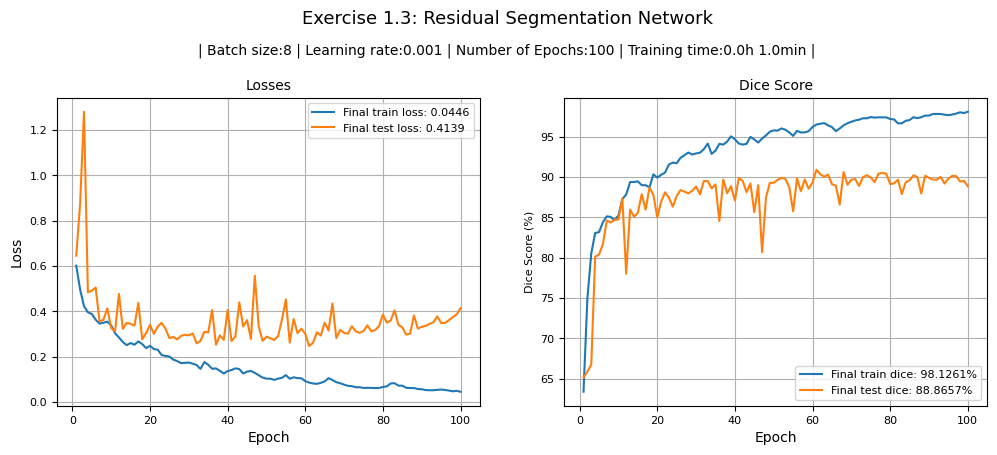

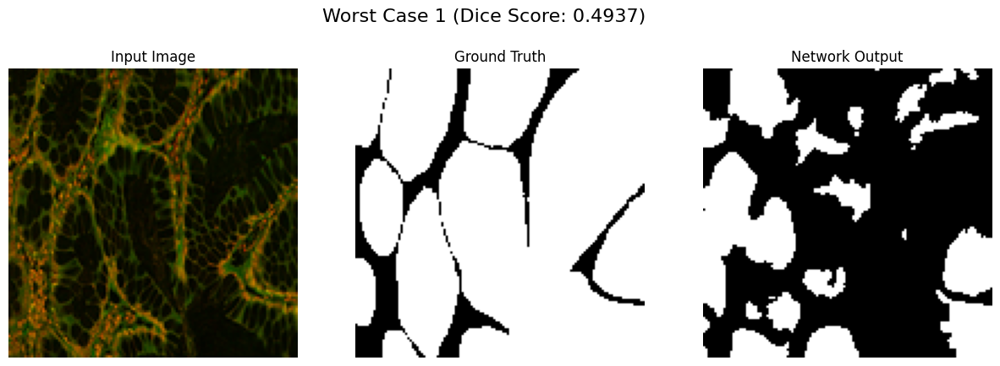

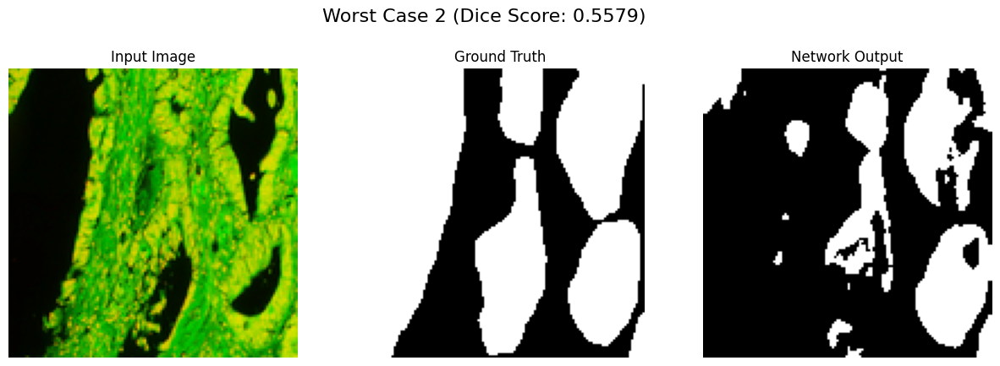

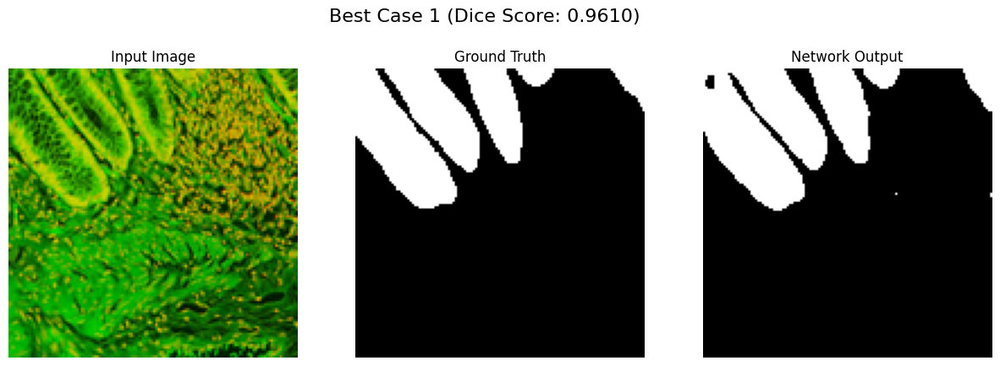

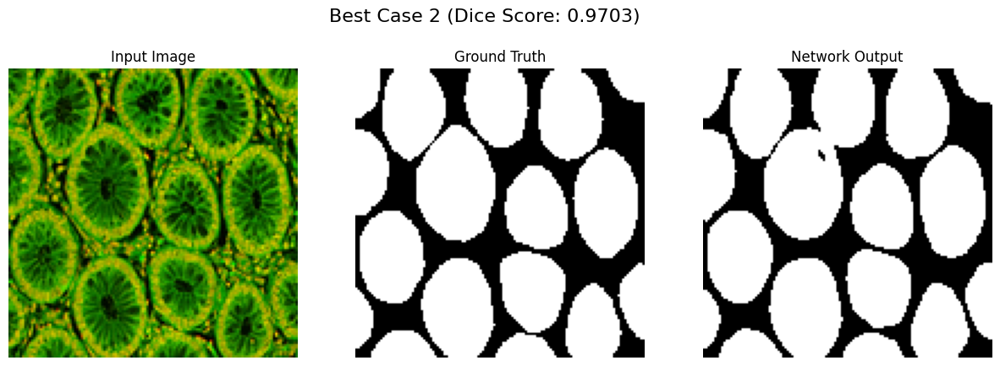

In [26]:
torch.manual_seed(42)
np.random.seed(42)

# 1. Initialize Model
model3 = ResidualUNet().to(device)
criterion = nn.BCEWithLogitsLoss() 

optimizer = torch.optim.Adam(model3.parameters(), lr=LR)

# 4. RUN TRAINING WITH VALIDATION LOADER (Requirement 1.4 feedback)
# Note: We pass 'val_loader' instead of 'test_loader' to tune the model.
t_loss, v_loss, t_dice, v_dice, duration = train_and_evaluate(
    model3, train_loader, val_loader, criterion, optimizer, EPOCHS
)

# 5. PLOT LEARNING CURVES (Requirement: Replace 'Accuracy' with 'Dice')
learning_curve_plot(
    "Exercise 1.3: Residual Segmentation Network",
    t_loss, v_loss, t_dice, v_dice, 
    BATCH_SIZE, LR, duration
)

# 6. QUALITATIVE INSPECTION (Requirement 1.1c)
# This will show the 2 best and 2 worst cases from the test set.
show_results_summary(model3, test_loader)

### Optimizations

#### Data Augmentation

In [27]:
# class WarwickData(Dataset):
#     def __init__(self, root, split="Train", augment=False):
#         self.split = split
#         self.augment = augment
#         self.split_path = os.path.join(root, split)
#         # Use sorted to ensure consistent indexing across runs
#         self.image_files = sorted([f for f in os.listdir(self.split_path) if f.startswith("image") and f.endswith(".png")])
        
#         self.normalize = transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])

#     def __len__(self):
#         return len(self.image_files)

#     def __getitem__(self, idx):
#         img_name = self.image_files[idx]
#         label_name = img_name.replace("image", "label")
        
#         img_path = os.path.join(self.split_path, img_name)
#         label_path = os.path.join(self.split_path, label_name)

#         image = Image.open(img_path).convert("RGB")
#         label = Image.open(label_path).convert("L")

#         if self.augment:
#             if random.random() > 0.5: image = TF.hflip(image); label = TF.hflip(label)
#             if random.random() > 0.5: image = TF.vflip(image); label = TF.vflip(label)
#             if random.random() > 0.5:
#                 angle = random.uniform(-15, 15)
#                 image = TF.rotate(image, angle)
#                 label = TF.rotate(label, angle)
#             image = transforms.ColorJitter(brightness=0.2, contrast=0.2)(image)

#         image = TF.to_tensor(image)
#         label = TF.to_tensor(label)
#         image = self.normalize(image)
#         mask = (label > 0.5).float()
#         return image, mask

# # Consistent Data Loading Setup
# data_root = "/kaggle/input/datasets/fahimrayhan/warwick-qu-dataset/WARWICK"
# full_train_ds = WarwickData(data_root, split="Train", augment=True)
# test_ds = WarwickData(data_root, split="Test", augment=False)

# # Proper validation split to avoid data leakage/augmentation in val
# train_idx, val_idx = random_split(range(len(full_train_ds)), [0.8, 0.2], generator=torch.Generator().manual_seed(42))

# # Create Subsets
# from torch.utils.data import Subset
# train_subset = Subset(full_train_ds, train_idx)
# val_subset = Subset(WarwickData(data_root, split="Train", augment=False), val_idx)

# train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
# val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
# test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# print(f"DataLoaders ready: {len(train_subset)} train, {len(val_subset)} val, {len(test_ds)} test samples.")

In [28]:
full_train_ds = WarwickData(data_root, split="Train", augment=True)
test_ds = WarwickData(data_root, split="Test", augment=False)

# Proper validation split to avoid data leakage/augmentation in val
train_idx, val_idx = random_split(range(len(full_train_ds)), [0.8, 0.2], generator=torch.Generator().manual_seed(42))

# Create Subsets
from torch.utils.data import Subset
train_subset = Subset(full_train_ds, train_idx)
val_subset = Subset(WarwickData(data_root, split="Train", augment=False), val_idx)

train_loader_aug = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_loader_aug = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
test_loader_aug = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoaders ready: {len(train_subset)} train, {len(val_subset)} val, {len(test_ds)} test samples.")

DataLoaders ready: 68 train, 17 val, 60 test samples.


#### Train on Augmented Data

Epoch 1/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 12.97it/s]


Epoch 1: Train Loss: 0.6080 | Val Dice: 63.80%


Epoch 2/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.16it/s]


Epoch 2: Train Loss: 0.5227 | Val Dice: 65.75%


Epoch 3/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.04it/s]


Epoch 3: Train Loss: 0.4737 | Val Dice: 66.24%


... (190 outputs left out)

Epoch 99/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.14it/s]


Epoch 99: Train Loss: 0.1797 | Val Dice: 91.39%


Epoch 100/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.06it/s]


Epoch 100: Train Loss: 0.1787 | Val Dice: 90.82%


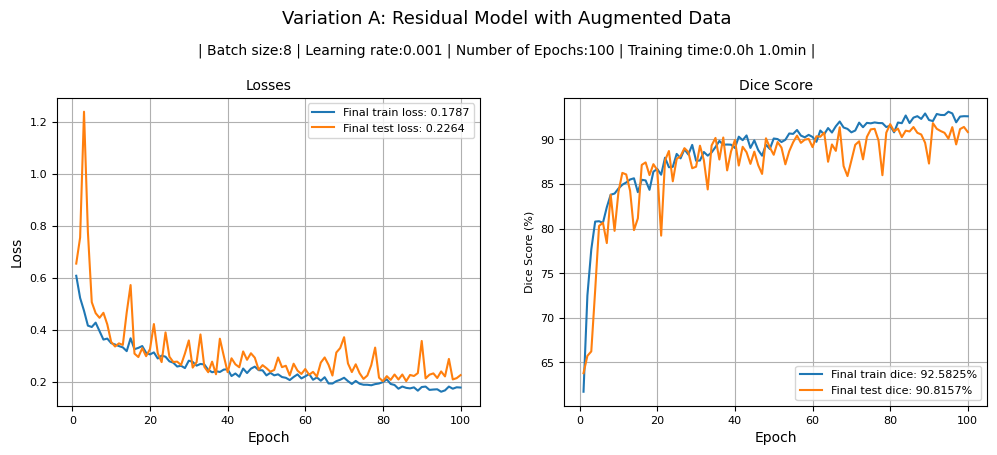

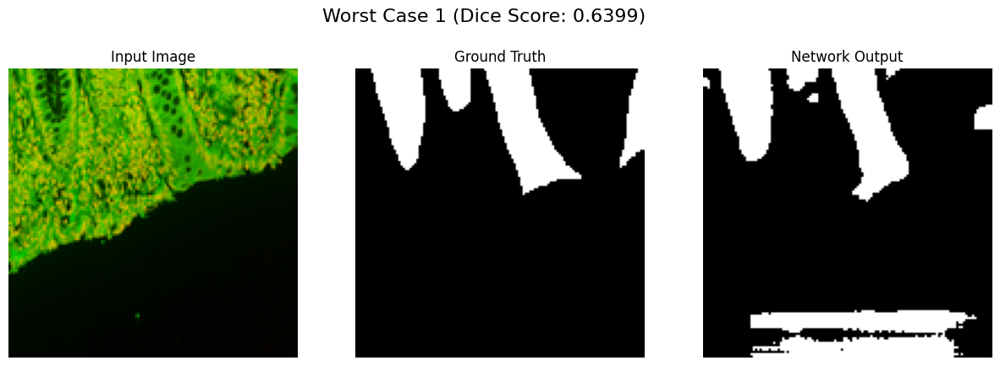

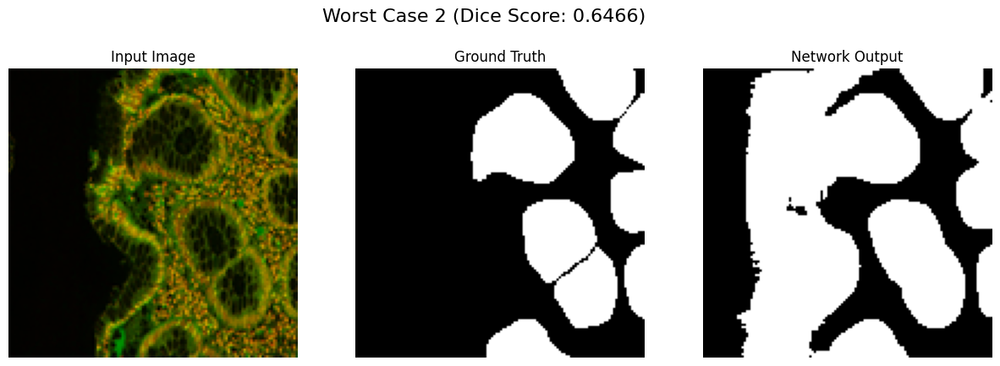

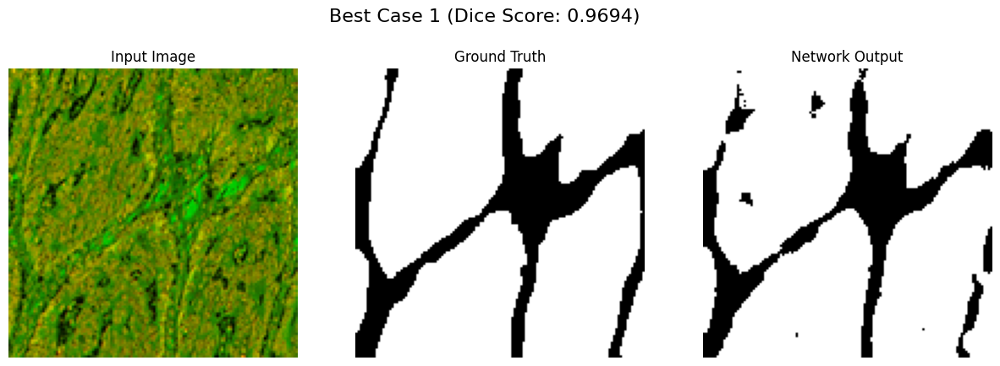

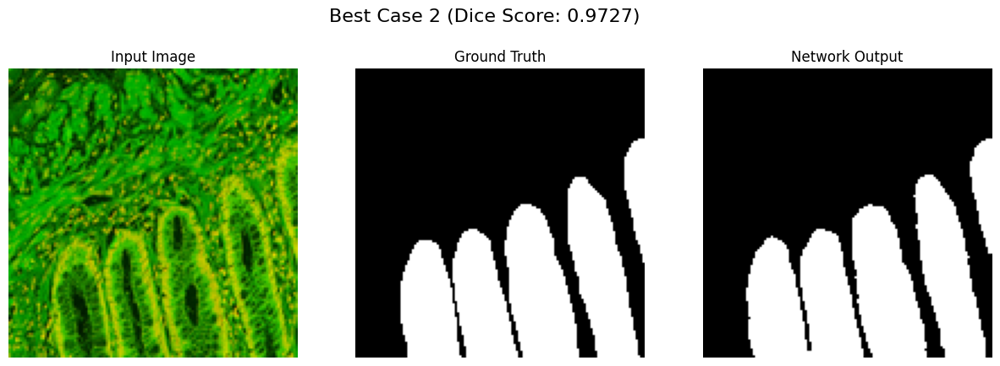

In [29]:
torch.manual_seed(42)
np.random.seed(42)

# 1. Initialize Model
model3_augmented = ResidualUNet().to(device)
criterion = nn.BCEWithLogitsLoss() 

optimizer = torch.optim.Adam(model3_augmented.parameters(), lr=LR)

# 4. RUN TRAINING WITH VALIDATION LOADER (Requirement 1.4 feedback)
# Note: We pass 'val_loader' instead of 'test_loader' to tune the model.
t_loss, v_loss, t_dice, v_dice, duration = train_and_evaluate(
    model3_augmented, train_loader_aug, val_loader_aug, criterion, optimizer, EPOCHS
)

# 5. PLOT LEARNING CURVES (Requirement: Replace 'Accuracy' with 'Dice')
learning_curve_plot(
    "Variation A: Residual Model with Augmented Data",
    t_loss, v_loss, t_dice, v_dice, 
    BATCH_SIZE, LR, duration
)

# 6. QUALITATIVE INSPECTION (Requirement 1.1c)
# This will show the 2 best and 2 worst cases from the test set.
show_results_summary(model3_augmented, test_loader_aug)

#### Lr Scheduling

Re-training Model 3 (ResidualUNet) with Data Augmentation & LR Scheduling...


Epoch 1/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 12.96it/s]


Epoch 1: Train Loss: 0.6130 | Val Dice: 65.80%


Epoch 2/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 14.93it/s]


Epoch 2: Train Loss: 0.5220 | Val Dice: 65.96%


Epoch 3/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.06it/s]


... (191 outputs left out)

Epoch 99/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 14.90it/s]


Epoch 99: Train Loss: 0.1923 | Val Dice: 91.73%


Epoch 100/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.02it/s]


Epoch 100: Train Loss: 0.1876 | Val Dice: 91.81%


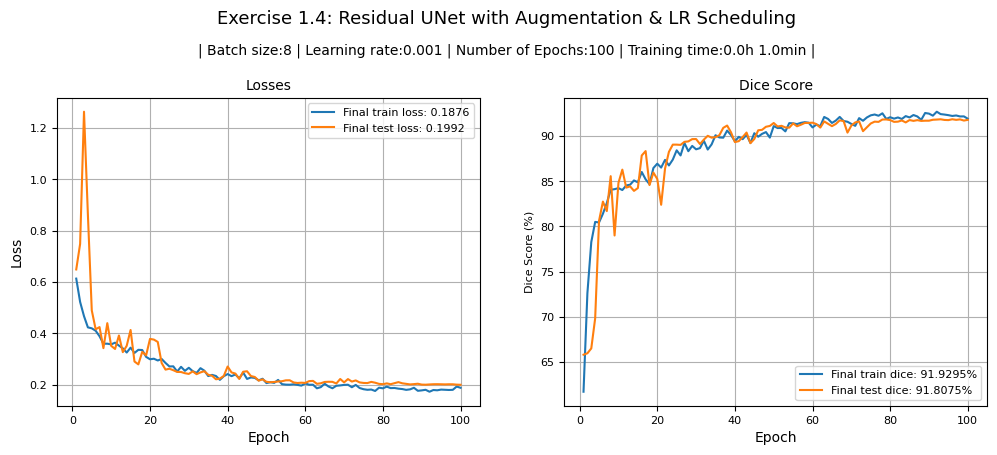

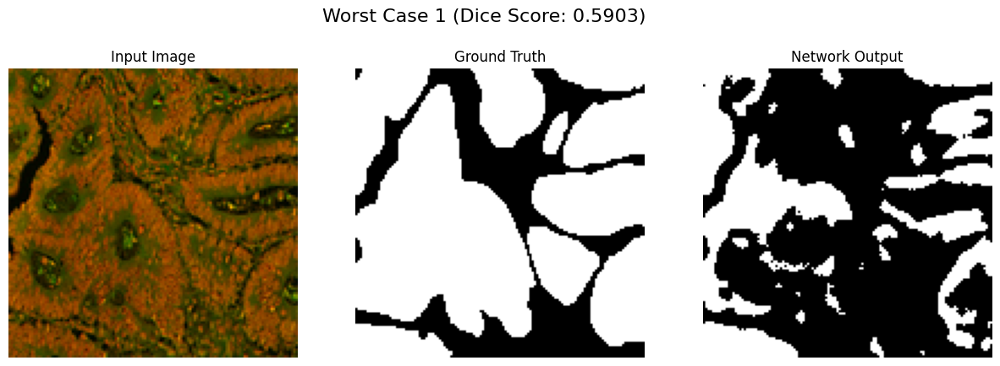

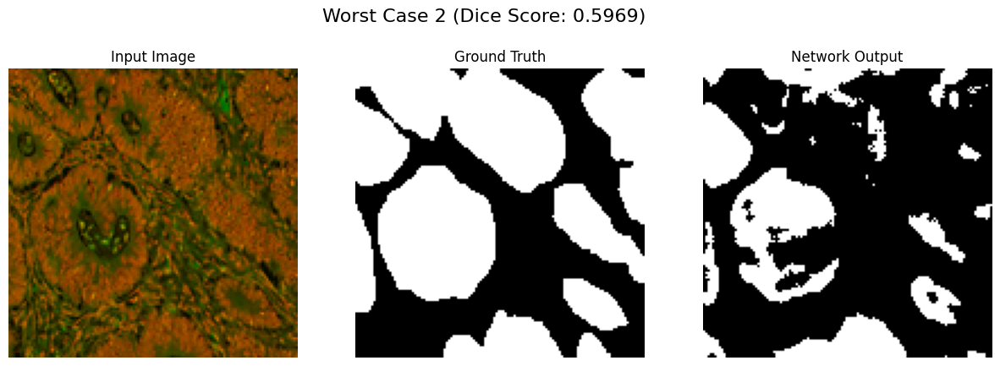

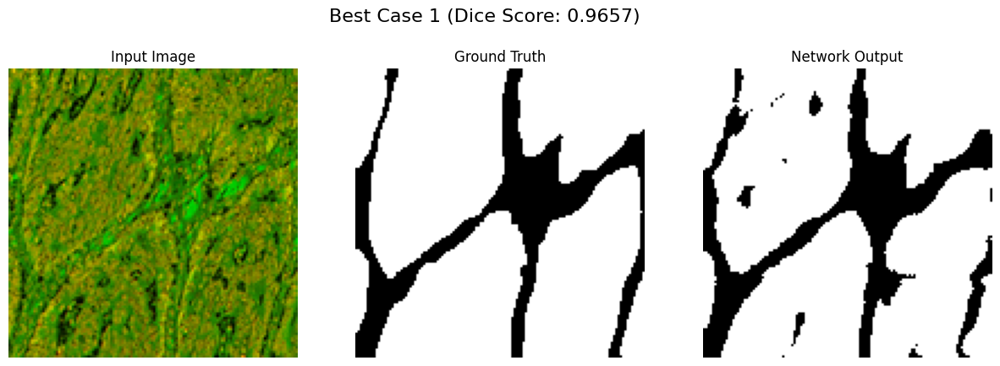

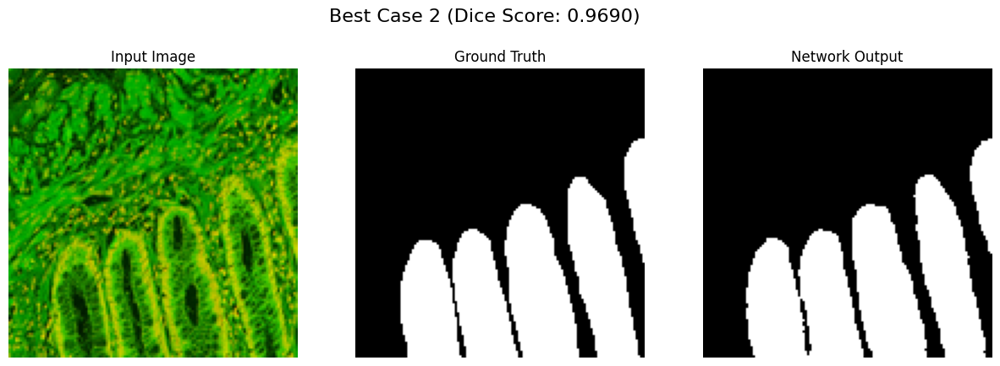

In [30]:
print("Re-training Model 3 (ResidualUNet) with Data Augmentation & LR Scheduling...")

torch.manual_seed(42)
model3_lrS = ResidualUNet().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model3_lrS.parameters(), lr=LR)

# Exercise 1.4: Learning Rate Scheduler
# Mode 'max' because we want to maximize Dice Score
# Note: 'verbose' argument removed for compatibility with latest torch version
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

t_loss, v_loss, t_dice, v_dice, duration = train_and_evaluate(
    model3_lrS, train_loader_aug, val_loader_aug, criterion, optimizer, EPOCHS, scheduler=scheduler
)

learning_curve_plot(
    "Exercise 1.4: Residual UNet with Augmentation & LR Scheduling",
    t_loss, v_loss, t_dice, v_dice,
    BATCH_SIZE, LR, duration
)

show_results_summary(model3_lrS, test_loader_aug)

#### Weight Decay

Training Cleaned Pipeline: ImprovedResidualUNet + Augmentation + LR Scheduling + Weight Decay


Epoch 1/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 13.38it/s]


Epoch 1: Train Loss: 0.6041 | Val Dice: 63.38%


Epoch 2/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 14.72it/s]


Epoch 2: Train Loss: 0.5116 | Val Dice: 65.84%


Epoch 3/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.06it/s]


... (191 outputs left out)

Epoch 99/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.20it/s]


Epoch 99: Train Loss: 0.1809 | Val Dice: 91.14%


Epoch 100/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 15.13it/s]


Epoch 100: Train Loss: 0.1847 | Val Dice: 89.52%


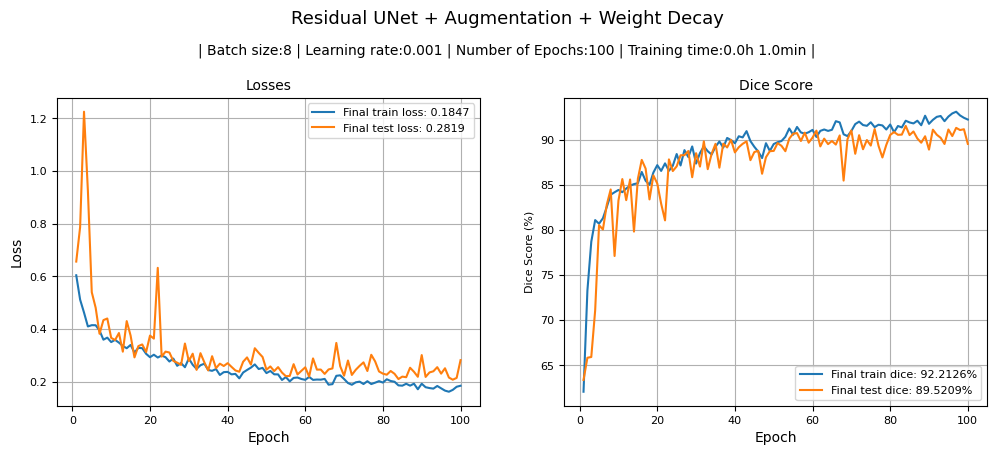

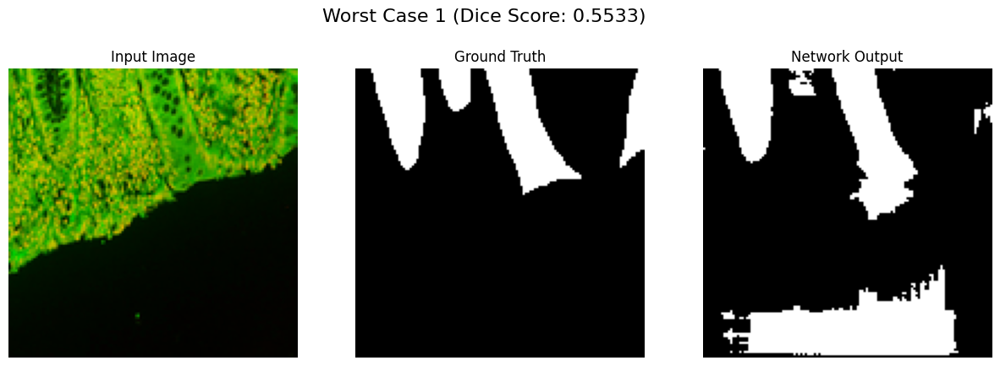

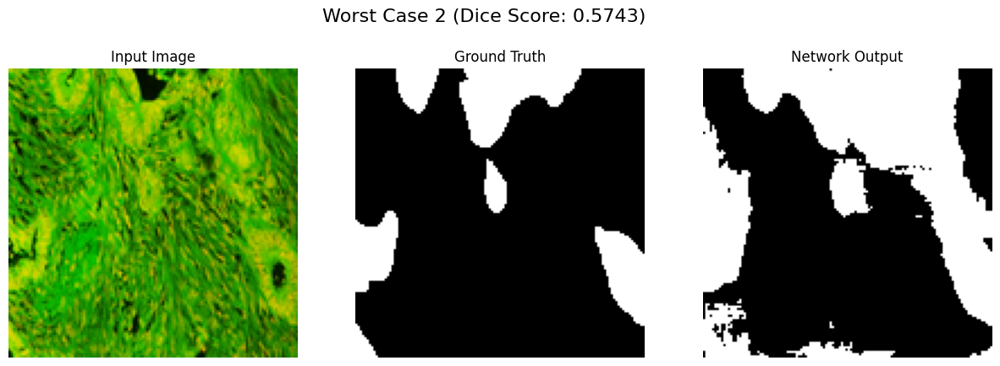

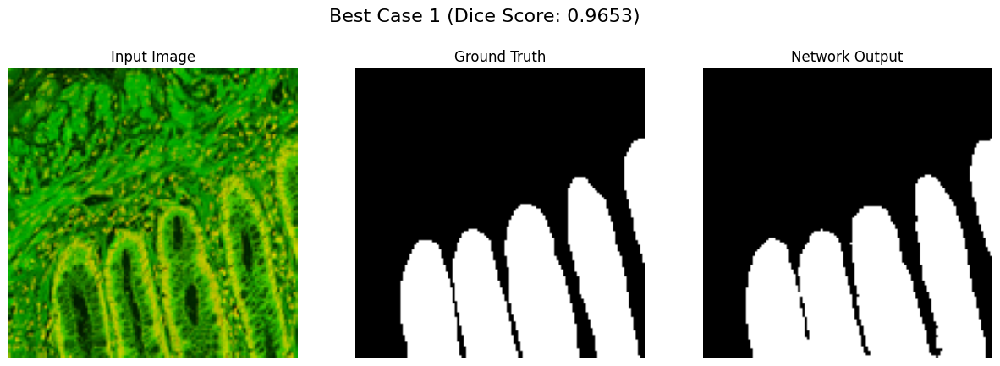

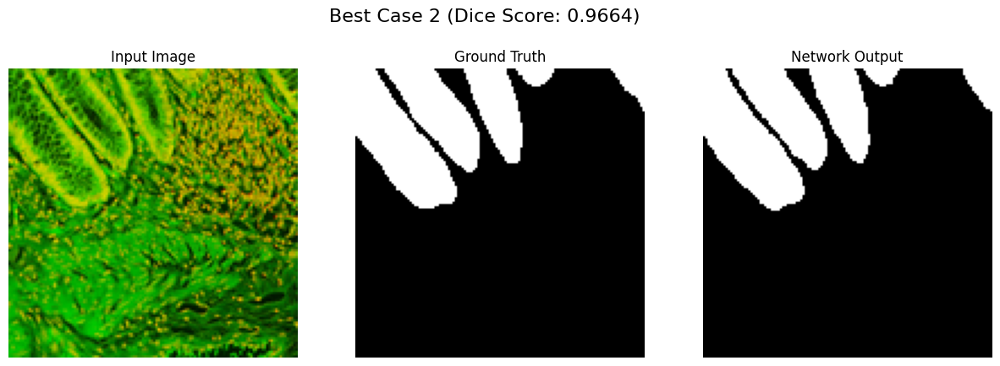

In [31]:
print("Training Cleaned Pipeline: ImprovedResidualUNet + Augmentation + LR Scheduling + Weight Decay")

torch.manual_seed(42)
model_final_decay = ResidualUNet().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_final_decay.parameters(), lr=1e-3, weight_decay=1e-4)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

t_loss, v_loss, t_dice, v_dice, duration = train_and_evaluate(
    model_final_decay, train_loader_aug, val_loader_aug, criterion, optimizer, EPOCHS
)

learning_curve_plot("Residual UNet + Augmentation + Weight Decay", t_loss, v_loss, t_dice, v_dice, BATCH_SIZE, 1e-3, duration)
show_results_summary(model_final_decay, test_loader_aug)

#### Best Combined

Training Cleaned Pipeline: ImprovedResidualUNet + Augmentation + LR Scheduling + Weight Decay


Epoch 1/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 13.43it/s]


Epoch 1: Train Loss: 0.6079 | Val Dice: 63.36%


Epoch 2/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 14.84it/s]


Epoch 2: Train Loss: 0.5135 | Val Dice: 65.90%


Epoch 3/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 14.32it/s]


... (191 outputs left out)

Epoch 99/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 14.79it/s]


Epoch 99: Train Loss: 0.1946 | Val Dice: 91.73%


Epoch 100/100 [Train]: 100%|██████████| 9/9 [00:00<00:00, 14.84it/s]


Epoch 100: Train Loss: 0.1839 | Val Dice: 91.70%


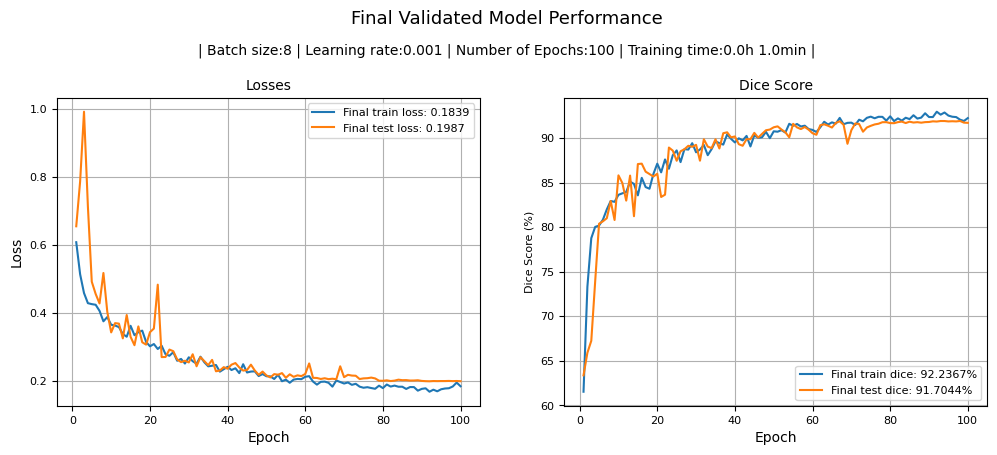

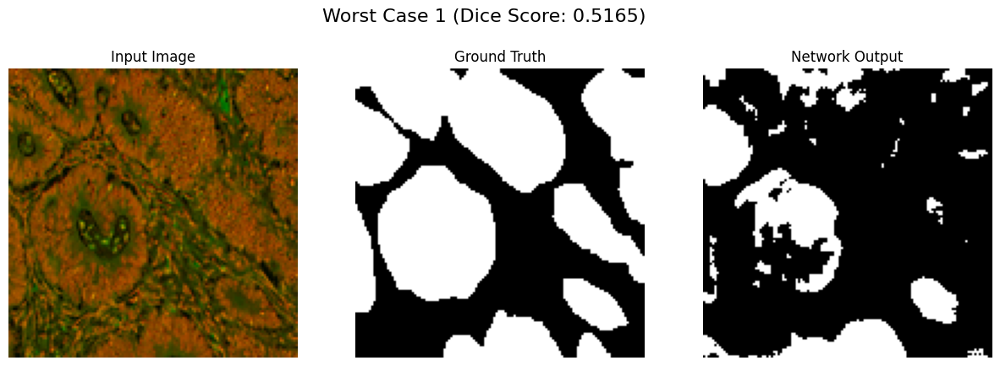

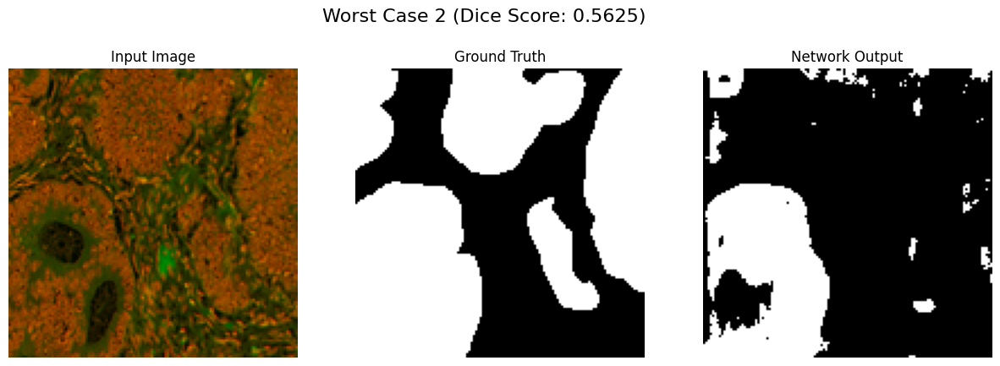

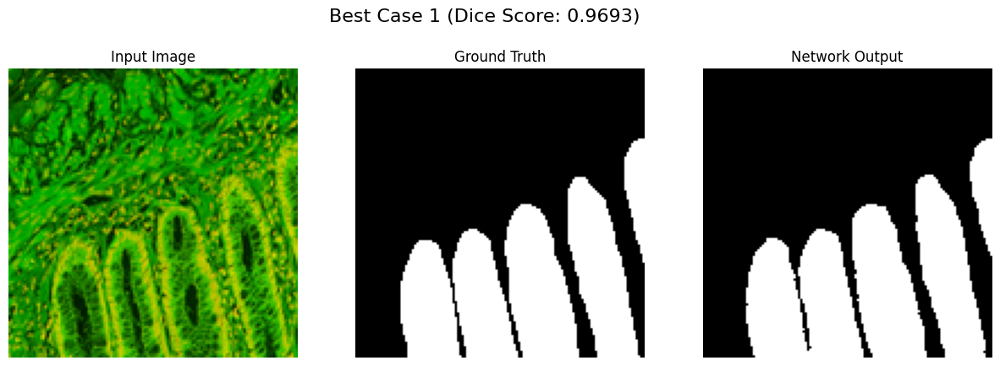

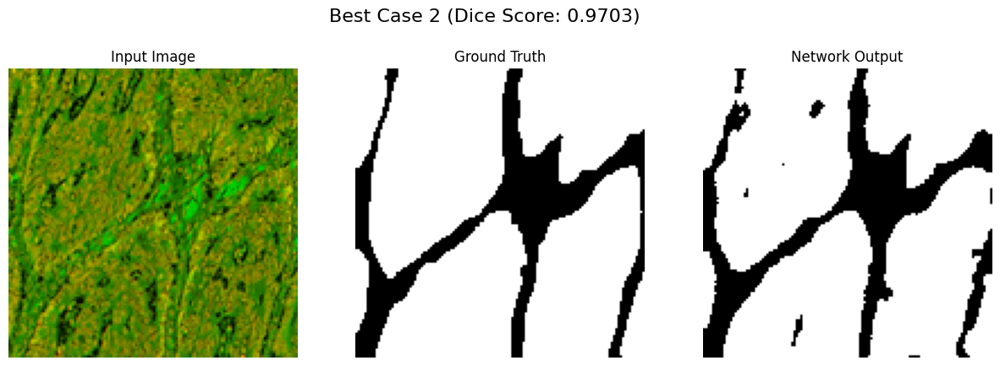

In [32]:
print("Training Cleaned Pipeline: ImprovedResidualUNet + Augmentation + LR Scheduling + Weight Decay")

torch.manual_seed(42)
model_final = ResidualUNet().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_final.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

t_loss, v_loss, t_dice, v_dice, duration = train_and_evaluate(
    model_final, train_loader_aug, val_loader_aug, criterion, optimizer, EPOCHS, scheduler=scheduler
)

learning_curve_plot("Final Validated Model Performance", t_loss, v_loss, t_dice, v_dice, BATCH_SIZE, 1e-3, duration)
show_results_summary(model_final, test_loader_aug)